# Лабораторная работа 3. Сегментация потребителей леденцов методом DBSCAN

## Цель и постановка задачи

По ответам респондентов необходимо выполнить кластеризацию методом DBSCAN,
определить полученное число групп и долю шума, оценить разделённость кластеров
и рассмотреть их профили по мотивам потребления.

## 1. Данные

Каждая строка представляет одного респондента, каждый столбец - оценку согласия
с высказыванием о цели потребления леденцов. Предполагаем, что большая оценка
означает более сильное согласие.

| Признак | Мотив потребления |
|---|---|
| V1 | Освежить дыхание |
| V2 | Чувствовать себя увереннее |
| V3 | Освежить полость рта |
| V4 | Избавиться от неприятного вкуса во рту |
| V5 | Заменить другие кондитерские изделия |
| V6 | Удовлетворить желание сладкого |
| V7 | Сконцентрироваться |
| V8 | Отвлечься на несколько минут и подумать |
| V9 | Облегчить боль в горле |
| V10 | Избавиться от заложенности носа |
| V11 | Улучшить самочувствие |

In [1]:
import pandas as pd


df = pd.read_csv("Леденцы.dat", sep=";")

display(df.head())
print("Размер данных:", df.shape)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Размер данных: (338, 11)


In [2]:
X = df[[f"V{i}" for i in range(1, 12)]].copy()

print("Количество пропусков:", X.isna().sum().sum())
print("Типы данных:")
print(X.dtypes)

display(X.describe())

Количество пропусков: 0
Типы данных:
V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


В файле 338 респондентов и 11 числовых признаков, пропуски отсутствуют.
Наблюдаемые оценки лежат в диапазоне 2–5. Совпадающие строки не удаляем:
одинаковые ответы могли дать разные люди, а удаление изменило бы
веса наблюдений и доли сегментов. Всего имеется 45 различных профилей ответов.

## 2. Подготовка и выбор метода

Используем DBSCAN — метод кластеризации на основе плотности.
Объект считается ядром, если в его окрестности радиуса `eps` находится
не менее `min_samples` объектов, включая его самого. Связанные ядра образуют
кластеры, к которым присоединяются граничные объекты. Наблюдения,
не попавшие в группы, получают метку шума −1.

В отличие от k-means число кластеров заранее не задаётся: оно зависит
от структуры данных и выбранных параметров. Кластеры могут иметь сложную форму;
расстояние между любыми двумя объектами одной группы не обязано быть меньше `eps`.

Стандартизируем признаки V1–V11: вычтем среднее и разделим на стандартное
отклонение каждого признака. Это делает их масштабы сопоставимыми.
Радиус `eps` далее относится к стандартизированному пространству.
Используем евклидову метрику, приближённо считая интервалы между соседними
баллами шкалы одинаковыми.

### Выбор параметров

Параметр `min_samples=12` задаёт рабочий порог плотности.
Зафиксируем его и сравним значения `eps` от 1 до 3 с шагом 0,1.
Это подбор радиуса при заданном пороге, а не совместная оптимизация
обоих параметров.

Для каждого варианта рассмотрим число кластеров, количество шумовых объектов
и две метрики качества, рассчитываемые без шума.

**Коэффициент силуэта** оценивает соответствие объекта своей группе
по сравнению с ближайшей другой группой:

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))},$$

где $a(i)$ — среднее расстояние до остальных объектов своего кластера,
а $b(i)$ — наименьшее среднее расстояние до объектов другого кластера.
Чем ближе средний силуэт к 1, тем лучше разделены группы; около 0 находятся
пограничные объекты, отрицательные значения указывают на возможное ошибочное
отнесение.

**Индекс Дэвиса—Болдина** сравнивает разброс внутри групп
с расстояниями между их центрами:

$$DB=\frac{1}{k}\sum_{i=1}^{k}\max_{j\ne i}
\frac{S_i+S_j}{\|\mu_i-\mu_j\|},$$

где $S_i$ — среднее расстояние объектов до центра $\mu_i$ своего кластера.
Для каждой группы выбирается наиболее неблагоприятное отношение,
затем значения усредняются. Чем меньше индекс, тем лучше.

Шумовые объекты не участвуют в расчёте этих метрик, поэтому качество
необходимо оценивать вместе с их количеством. Если метрики не определены
для полученного разбиения, в таблице остаётся `NaN`.

,eps,n_clusters,n_noise,silhouette,davies_bouldin
0,1.0,6,124,1.0000,0.0000
1,1.1,5,88,0.9250,0.1395
2,1.2,5,88,0.9250,0.1395
3,1.3,6,69,0.9063,0.2083
4,1.4,6,69,0.9063,0.2083
5,1.5,6,59,0.8750,0.2279
6,1.6,7,42,0.8566,0.3164
7,1.7,7,31,0.8164,0.4229
8,1.8,6,25,0.7363,0.4686
9,1.9,5,13,0.7069,0.4669


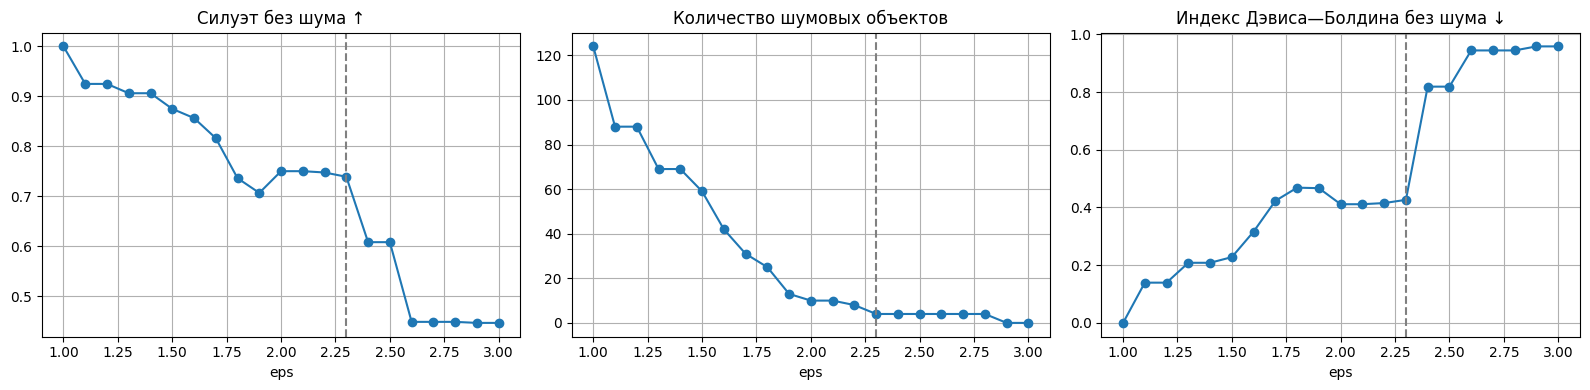

In [3]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

eps_results = []
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for eps in np.arange(1.0, 3.01, 0.1).round(2):
    labels_eps = DBSCAN(
        eps=float(eps),
        min_samples=12,
        metric="euclidean"
    ).fit_predict(X_scaled)

    mask = labels_eps != -1
    n_clusters_eps = len(np.unique(labels_eps[mask]))
    n_noise_eps = int((~mask).sum())

    silhouette = np.nan
    davies_bouldin = np.nan

    if 2 <= n_clusters_eps < mask.sum():
        silhouette = silhouette_score(
            X_scaled[mask], labels_eps[mask]
        )
        davies_bouldin = davies_bouldin_score(
            X_scaled[mask], labels_eps[mask]
        )

    eps_results.append({
        "eps": eps,
        "n_clusters": n_clusters_eps,
        "n_noise": n_noise_eps,
        "silhouette": silhouette,
        "davies_bouldin": davies_bouldin
    })

eps_results = pd.DataFrame(eps_results)
display(eps_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column, title in zip(
    axes,
    ["silhouette", "n_noise", "davies_bouldin"],
    [
        "Силуэт без шума ↑",
        "Количество шумовых объектов",
        "Индекс Дэвиса—Болдина без шума ↓"
    ]
):
    ax.plot(eps_results["eps"], eps_results[column], marker="o")
    ax.axvline(2.3, color="gray", linestyle="--")
    ax.set_xlabel("eps")
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()

### Обоснование выбора радиуса

При `eps=1` силуэт равен 1, а индекс Дэвиса—Болдина — 0.
Однако при этом 124 человека, или 36,69% выборки, отнесены к шуму.
В оставшихся группах ответы полностью совпадают, поэтому внутрикластерные
расстояния равны нулю. Идеальные значения характеризуют эти группы одинаковых
ответов, но не учитывают исключённую часть выборки.

В диапазоне `eps=2.0–2.3` сохраняются четыре кластера. Силуэт составляет
примерно 0,74–0,75, индекс Дэвиса—Болдина — 0,41–0,43, а число шумовых
объектов уменьшается с 10 до 4. При переходе к `eps=2.4` две группы
объединяются: остаётся три кластера, силуэт снижается до 0,6084,
а индекс Дэвиса—Болдина возрастает до 0,8187. Шумовых объектов по-прежнему четыре,
то есть ухудшение качества не сопровождается увеличением охвата выборки.

Выбираем **`eps=2.3`** — последнее проверенное значение перед этим скачком.
Оно сохраняет содержательное разделение на четыре группы и позволяет отнести
к кластерам 334 из 338 респондентов. Пунктир на графиках отмечает этот выбор.
Это компромисс между разделённостью групп и долей шума, а не максимум
одной метрики.

## 3. Кластеризация

Обучим итоговую модель с `eps=2.3` и `min_samples=12`.
Число кластеров определяется алгоритмом. Номера групп условны,
метка −1 обозначает шум.

In [4]:
dbscan = DBSCAN(
    eps=2.3,
    min_samples=12,
    metric="euclidean"
)

labels = dbscan.fit_predict(X_scaled)

df["cluster_dbscan"] = labels

n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Количество кластеров:", n_clusters)
print("Количество шумовых точек:", n_noise)

print(df["cluster_dbscan"].value_counts().sort_index())

Количество кластеров: 4
Количество шумовых точек: 4
cluster_dbscan
-1      4
 0    110
 1    104
 2     61
 3     59
Name: count, dtype: int64


Получены четыре кластера из 110, 104, 61 и 59 респондентов.
Четыре наблюдения отнесены к шуму. Таким образом, группами охвачено
98,82% выборки.

## 4. Оценка результата

Рассчитаем средний коэффициент силуэта только по объектам, попавшим в кластеры,
и отдельно укажем долю шума.

In [5]:
mask = labels != -1

if len(set(labels[mask])) >= 2:
    score = silhouette_score(X_scaled[mask], labels[mask])
    print("Silhouette Score:", score)
else:
    print("Недостаточно кластеров для расчёта силуэта")
print(f"Доля шума: {n_noise / len(labels):.2%}")

Silhouette Score: 0.7391838326278822
Доля шума: 1.18%


Итоговый силуэт равен **0,7392**, индекс Дэвиса—Болдина для этого же
разбиения — **0,4264** (он приведён в таблице подбора `eps`).
Метрики указывают на достаточно компактные и разделённые группы.
Доля шума составляет **1,18%**.

Эти показатели рассчитаны по 334 объектам после исключения шума.
Их нельзя напрямую сравнивать с метриками k-means из лаб2:
там использовались исходные оценки и все 338 респондентов.

## 5. Двумерная визуализация

Для изображения кластеров на плоскости используем метод главных компонент (PCA).
Первые две компоненты сохраняют примерно 75,21% общей дисперсии.
Цветом обозначены группы, серым — шумовые объекты.

DBSCAN работает со всеми 11 стандартизированными признаками; PCA используется
только для визуализации. Рисунок не передаёт все расстояния исходного
пространства, а совпадающие ответы могут накладываться друг на друга.

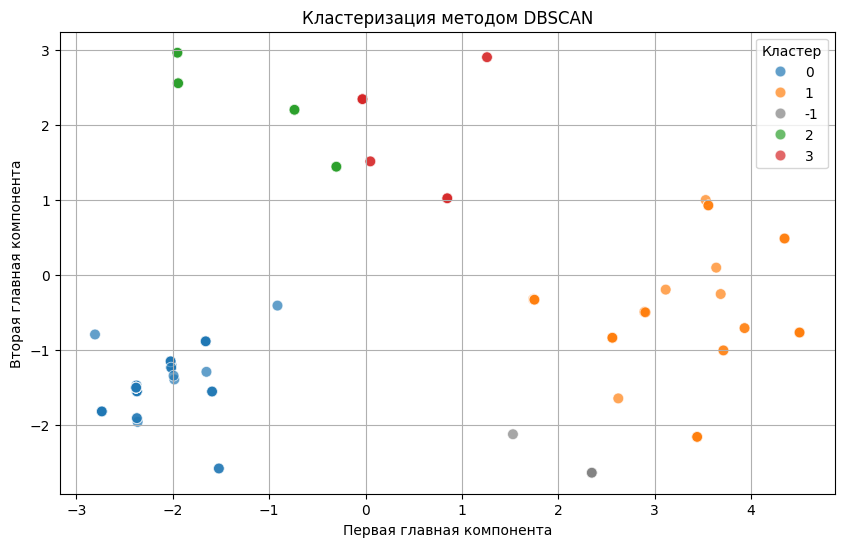

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

df_plot = pd.DataFrame(X_2d, columns=["PC1", "PC2"])
df_plot["cluster"] = labels.astype(str)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_plot,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette={
        str(c): "gray" if c == -1 else sns.color_palette("tab10")[c % 10]
        for c in np.unique(labels)
    },
    s=60,
    alpha=0.7
)

plt.title("Кластеризация методом DBSCAN")
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend(title="Кластер")
plt.grid(True)
plt.show()

## 6. Профили и содержательная интерпретация кластеров

Для интерпретации рассмотрим средние исходные оценки V1–V11 внутри групп.
Более высокие оценки показывают ведущие мотивы потребления.
Шумовые точки не включаем в расчёт кластерных профилей.

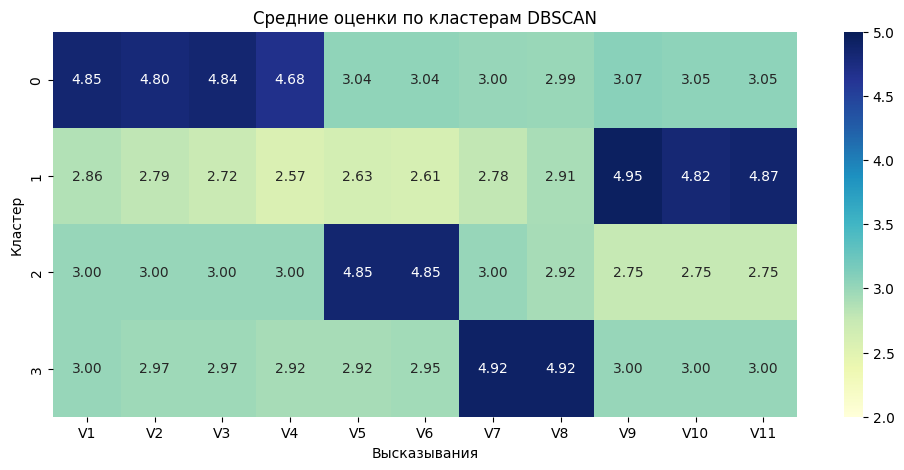

In [7]:
profile = (
    df[df["cluster_dbscan"] != -1]
    .groupby("cluster_dbscan")[X.columns]
    .mean()
)

if not profile.empty:
    plt.figure(figsize=(12, 5))

    sns.heatmap(
        profile,
        annot=True,
        cmap="YlGnBu",
        vmin=2,
        vmax=5,
        fmt=".2f"
    )

    plt.title("Средние оценки по кластерам DBSCAN")
    plt.xlabel("Высказывания")
    plt.ylabel("Кластер")
    plt.show()
else:
    print("DBSCAN не выделил кластеров")

### Содержательная интерпретация четырёх групп

| Кластер | Человек | Доля всей выборки | Условное название | Основание |
|---|---:|---:|---|---|
| 1 | 110 | 32,54% | Уверенность | V1=4,85; V2=4,80; V3=4,84; V4=4,68 |
| 2 | 104 | 30,77% | Облегчение дискомфорта | V9=4,95; V10=4,82; V11=4,87 |
| 3 | 61 | 18,05% | Сладкоежки | V5=4,85; V6=4,85 |
| 4 | 59 | 17,46% | Концентрация | V7=4,92; V8=4,92 |

**Кластер 1. Уверенность.** Устранение неприятного вкуса во рту, свежесть
дыхания и полости рта сочетаются с желанием чувствовать себя увереннее.
Остальные мотивы имеют средние оценки около 3. В выборке это самый большой сегмент.

**Кластер 2. Облегчение дискомфорта.** Леденцы прежде всего ассоциируются
с облегчением боли в горле, заложенности носа и улучшением самочувствия.
Остальные средние оценки ниже 3. Это описание заявленных мотивов,
а не доказательство лечебного эффекта продукта.

**Кластер 3. Сладкоежки.** Леденцы рассматриваются как сладость
и альтернатива другим кондитерским изделиям. Остальные мотивы выражены слабее.

**Кластер 4. Концентрация.** Высокие оценки V7–V8 показывают связь потребления
с сосредоточением и возможностью ненадолго отвлечься и подумать.
Делать выводы о профессии или возрасте участников по этим признакам нельзя.

Названия описывают средние профили, а не каждого участника без исключения.
Доли рассчитаны от всех 338 респондентов, поэтому без шумовых объектов
суммируются примерно в 98,82%.

## 7. Выводы

Методом DBSCAN при `eps=2.3` и `min_samples=12` выделены четыре группы
потребителей леденцов: «Уверенность», «Облегчение дискомфорта», «Сладкоежки»
и «Концентрация». В кластеры включены 334 человека, четыре наблюдения
отнесены к шуму — 1,18% выборки.

Выбор радиуса основан на совместном рассмотрении силуэта, индекса
Дэвиса—Болдина, числа кластеров и количества шумовых объектов.
При выбранном радиусе силуэт составляет 0,7392, индекс Дэвиса—Болдина — 0,4264.
Дальнейшее увеличение до следующего проверенного значения 2,4 объединяет
две группы и заметно ухудшает метрики, не уменьшая число шумовых точек.

Самый крупный сегмент — «Уверенность»: 110 человек, или 32,54% выборки.
Все четыре группы имеют различимые ведущие мотивы и содержательную интерпретацию.
Сохранение четырёх кластеров при проверенных радиусах от 2,0 до 2,3 поддерживает
выбор такого уровня сегментации при фиксированном `min_samples=12`.
Устойчивость к изменению состава выборки в этой работе не проверялась.